# 04 — LightGBM : corriger le KNN ancré (stacking)

Le KNN ancré (notebook 03) fait 82,1 W sur dev, mais encore 99 à 109 W sur les trous longs. Il ignore une partie de l'information disponible : la valeur de la courbe la veille au même créneau, le désaccord entre ses voisines, la position dans le trou… Un **LightGBM** apprend *quand et comment* corriger le KNN à partir de ce contexte.

**Règles** : apprentissage uniquement sur des courbes du **réservoir** (jamais dev, holdout ni real) ; réglages par **validation croisée sur ces données d'entraînement** ; **dev** ne voit que les deux modèles finaux (un par formulation) et le test du plancher à 0 ; vérification sur **real** ; **holdout** intouché.

| Section | Contenu |
|---|---|
| a | Données d'entraînement sans fuite |
| b | Petite grille, validation croisée groupée par courbe, MLflow |
| c | Évaluation sur dev, plancher à 0 |
| d | Vérification sur real |
| e | Ce que le modèle a appris : importance des variables et SHAP |
| f | Un exemple |
| — | Suivre les runs dans MLflow ; constat → conséquence |

In [1]:
# Imports et configuration
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.ticker import PercentFormatter

from enedis_imputation import SEED
from enedis_imputation.features import FEATURES, build_features
from enedis_imputation.gbm import (
    TRAIN_CACHE,
    GBMConfig,
    build_training_set,
    config_dict,
    make_method,
    train_cached,
)
from enedis_imputation.holes import LENGTH_LABELS, hole_runs, length_bucket
from enedis_imputation.knn import BEST_DISTANCE, BEST_PREDICTOR, anchored_knn, search
from enedis_imputation.methods import linear_interpolation
from enedis_imputation.tracking import TRACKING_URI, log_evaluation, setup_mlflow
from enedis_imputation.validation import evaluate, load_split, motif_masks, paired_difference
from enedis_imputation.viz import PALETTE as P
from enedis_imputation.viz import method_color, plot_imputation, save_fig, set_conclusion, set_style

set_style()
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
dev, real = load_split("dev"), load_split("real")  # le holdout n'est pas chargé
experiment_id = setup_mlflow("04_lightgbm")
print("MLflow :", TRACKING_URI)

2026/11/06 19:38:12 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at /Users/thibaudperes/projets/enedis-imputation/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/mlflow-trace-instrumentation/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/11/06 19:38:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/06 19:38:14 INFO mlflow.store.db.utils: Updating database tables


MLflow : sqlite:////Users/thibaudperes/projets/enedis-imputation/mlruns/mlflow.db


## a. Données d'entraînement sans fuite

- **Cibles** : 8 000 courbes tirées du réservoir (hors doubles exacts), chacune trouée par **2 motifs réels différents** → 16 000 courbes trouées, une ligne par point manquant.
- **Prédictions KNN hors pli** : les 8 000 courbes sont réparties en 5 plis ; celles du pli k (et leurs deux copies) sont remplies avec un réservoir qui **exclut tout le pli k**. Chaque pli cherche ainsi ses voisines parmi ~14 400 courbes, comme dev parmi 16 001. Un test pytest vérifie qu'aucune courbe n'est sa propre voisine.
- **Variables** (`features.py`) : 24 variables, qui ne dépendent que des points observés et du réservoir.

In [2]:
motifs = motif_masks().to_numpy()
ts = build_training_set(dev.reservoir, motifs)  # ~35 s la première fois, puis relu du cache
ts_key = TRAIN_CACHE.with_suffix(".json").read_text()
print(
    f"{len(ts.y):,} lignes × {ts.X.shape[1]} variables ({ts.X.to_numpy().nbytes / 1e6:.0f} Mo), "
    f"{len(np.unique(ts.groups)):,} courbes d'origine".replace(",", " ")
)

# Les prédictions de base, hors pli, sont-elles aussi bonnes que sur dev ?
cls = length_bucket(ts.X["hole_len"].to_numpy())
base = (
    pd.DataFrame(
        {
            "KNN ancré (hors pli)": np.abs(ts.X["knn_anchored"].to_numpy() - ts.y),
            "Interpolation": np.abs(ts.X["interp"].to_numpy() - ts.y),
        }
    )
    .groupby(cls, observed=False)
    .mean()
)
base.loc["toutes"] = [np.abs(ts.X[c].to_numpy() - ts.y).mean() for c in ["knn_anchored", "interp"]]
display(base.T.round(1))
display(ts.X.isna().mean().rename("part de valeurs manquantes").to_frame().T.round(3))

2 061 706 lignes × 24 variables (198 Mo)  8 000 courbes d'origine


,1,2,3-6,7-48,>48,toutes
KNN ancré (hors pli),59.30,67.80,72.20,97.10,99.90,79.50
Interpolation,60.20,69.00,74.90,141.80,148.50,102.00


,knn_anchored,knn_scaled,interp,nb_std,nb_iqr,nb_dist,hole_len,dist_left,dist_right,rel_pos,...,lag_m48,lag_p48,lag_m336,lag_p336,slot_median,left_val,right_val,curve_mean,curve_std,curve_zero_share
part de valeurs manquantes,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.02,0.00,0.00,...,0.16,0.16,0.40,0.40,0.00,0.02,0.00,0.00,0.00,0.00


## b. Petite grille, validation croisée groupée par courbe

Deux formulations — **résidu** (le modèle prédit y − KNN ancré) et **direct** (il prédit y) — croisées avec deux tailles d'arbres (63 ou 255 feuilles) : 4 configurations. Objectif **L1**. Taux d'apprentissage 0,1 et la moitié des lignes par arbre : 2,5 fois plus rapide que 0,05 sur toutes les lignes, pour 0,4 W de perte mesurée sur un pli.

Pour chaque configuration : **validation croisée en 3 plis groupés par courbe** (les deux copies d'une courbe restent ensemble) avec arrêt anticipé sur le pli de validation, puis entraînement final sur tout le jeu avec le nombre moyen d'arbres. Les modèles sont mis en cache (`data/processed/gbm_models/`) ; les temps affichés sont ceux du calcul d'origine. Chaque configuration est un run MLflow.

In [3]:
grid = [
    GBMConfig(formulation, leaves) for formulation in ["residual", "direct"] for leaves in [63, 255]
]
trained, run_ids, rows = {}, {}, {}
for cfg in grid:
    cv, booster, fit_seconds = train_cached(ts, cfg, ts_key)
    trained[cfg] = booster
    importance = pd.Series(booster.feature_importance("gain"), index=FEATURES)
    with mlflow.start_run(run_name=cfg.label) as run:
        mlflow.log_params(
            config_dict(cfg)
            | {
                "train_rows": len(ts.y),
                "train_curves": 8000,
                "motifs_per_curve": 2,
                "knn_folds": 5,
                "cv_folds": 3,
            }
        )
        mlflow.log_metrics(
            {
                "cv_mae": cv.mae,
                "cv_best_rounds_mean": float(np.mean(cv.best_rounds)),
                "cv_seconds": cv.seconds,
                "fit_seconds": fit_seconds,
            }
        )
        mlflow.log_text(
            (importance / importance.sum()).sort_values(ascending=False).to_csv(),
            "importance_gain.csv",
        )
        run_ids[cfg] = run.info.run_id
    rows[cfg.label] = {
        "formulation": cfg.formulation,
        "feuilles": cfg.num_leaves,
        "MAE CV (W)": cv.mae,
        "arbres (par pli)": cv.best_rounds,
        "CV (s)": cv.seconds,
        "entraînement final (s)": fit_seconds,
    }
grid_table = pd.DataFrame(rows).T
display(grid_table)

# Meilleure configuration de chaque formulation, choisie sur la CV (pas sur dev)
chosen = {
    f: min(
        (c for c in grid if c.formulation == f), key=lambda c: grid_table.loc[c.label, "MAE CV (W)"]
    )
    for f in ["residual", "direct"]
}
print("Retenues :", {f: c.label for f, c in chosen.items()})

,formulation,feuilles,MAE CV (W),arbres (par pli),CV (s),entraînement final (s)
"LightGBM résidu, 63 feuilles",residual,63,70.24,"[1748, 1339, 1353]",535.42,173.71
"LightGBM résidu, 255 feuilles",residual,255,70.26,"[424, 379, 447]",320.33,84.02
"LightGBM direct, 63 feuilles",direct,63,70.55,"[1787, 1876, 1320]",589.10,186.48
"LightGBM direct, 255 feuilles",direct,255,70.65,"[519, 543, 579]",397.71,127.12


Retenues : {'residual': 'LightGBM résidu, 63 feuilles', 'direct': 'LightGBM direct, 63 feuilles'}


**Constat → conséquence (grille)**

- Les **quatre configurations se tiennent à 0,4 W** en validation croisée (70,2 à 70,7 W), contre 79,5 W pour le KNN ancré hors pli sur les mêmes lignes. Le gain vient du modèle, pas du réglage fin.
- **Le résidu bat légèrement le direct** (70,24 contre 70,55 W avec 63 feuilles) : partir du KNN ancré et apprendre une correction est plus facile que tout réapprendre.
- 63 et 255 feuilles se valent, mais 255 feuilles converge en 3 à 4 fois moins d'arbres : **2 fois plus rapide** (7 min contre 12 min pour la validation croisée et l'entraînement final).
- → Retenues par la CV, sans regarder dev : **résidu 63 feuilles** et **direct 63 feuilles**.

## c. Évaluation sur dev

Trois évaluations LightGBM seulement sur dev : les deux formulations retenues, puis la meilleure **sans** plancher à 0. Le KNN ancré et l'interpolation sont réévalués pour les comparaisons appariées.

In [4]:
on_dev = {
    "Interpolation linéaire": evaluate(linear_interpolation, dev, name="Interpolation linéaire"),
    "KNN ancré": evaluate(anchored_knn, dev, name="KNN ancré"),
}
gbm_dev = {}
for f, cfg in chosen.items():
    gbm_dev[f] = evaluate(make_method(trained[cfg], cfg), dev, name=cfg.label)
    with mlflow.start_run(run_id=run_ids[cfg]):
        log_evaluation(gbm_dev[f])

best_f = min(gbm_dev, key=lambda f: gbm_dev[f].mae)
best_cfg = chosen[best_f]
on_dev["LightGBM"] = gbm_dev[best_f]

table = pd.DataFrame(
    {
        name: [*r.by_class["mae"].to_numpy(), r.mae]
        for name, r in {**on_dev, **{chosen[f].label: r for f, r in gbm_dev.items()}}.items()
    },
    index=[*LENGTH_LABELS, "toutes"],
).T
display(table.round(1))
print(
    f"Retenu : {best_cfg.label} — dev {gbm_dev[best_f].mae:.2f} W, "
    f"IC95 [{gbm_dev[best_f].ci[0]:.1f}, {gbm_dev[best_f].ci[1]:.1f}]"
)
display(
    paired_difference(gbm_dev[best_f], on_dev["KNN ancré"])
    .rename_axis("LightGBM − KNN ancré (W), dev")
    .round(2)
)
other = "direct" if best_f == "residual" else "residual"
d = paired_difference(gbm_dev[other], gbm_dev[best_f]).loc["toutes"]
print(
    f"{chosen[other].label} − {best_cfg.label} : {d['différence']:+.2f} W "
    f"[{d['IC bas']:+.2f}, {d['IC haut']:+.2f}]"
)

,1,2,3-6,7-48,>48,toutes
Interpolation linéaire,62.20,71.90,77.40,143.40,154.10,104.30
KNN ancré,60.90,70.10,75.30,99.10,108.90,82.10
LightGBM,55.80,63.00,68.00,85.70,95.70,72.70
"LightGBM résidu, 63 feuilles",55.80,63.00,68.00,85.70,95.70,72.70
"LightGBM direct, 63 feuilles",56.30,63.50,67.80,85.80,95.70,72.90


Retenu : LightGBM résidu, 63 feuilles — dev 72.67 W, IC95 [69.0, 76.3]


,différence,IC bas,IC haut
"LightGBM − KNN ancré (W), dev",,,
1,-5.06,-5.49,-4.64
2,-7.01,-7.70,-6.31
3-6,-7.24,-9.00,-5.64
7-48,-13.41,-14.83,-12.04
>48,-13.27,-16.00,-10.79
toutes,-9.45,-10.19,-8.71


LightGBM direct, 63 feuilles − LightGBM résidu, 63 feuilles : +0.27 W [+0.14, +0.39]


In [5]:
# Effet du plancher à 0 : combien de prédictions brutes seraient négatives, et à quel coût ?
no_clip = evaluate(
    make_method(trained[best_cfg], best_cfg, clip=False),
    dev,
    name=best_cfg.label + " (sans plancher à 0)",
)
d = paired_difference(no_clip, gbm_dev[best_f]).loc["toutes"]
print(
    f"Sans plancher : {no_clip.mae:.3f} W ; avec : {gbm_dev[best_f].mae:.3f} W ; "
    f"écart {d['différence']:+.3f} W [{d['IC bas']:+.3f}, {d['IC haut']:+.3f}]"
)
nb_dev = search(dev.X_holed, dev.reservoir, BEST_DISTANCE, k_max=BEST_PREDICTOR.k)
feats_dev, t_dev, c_dev = build_features(dev.X_holed, dev.reservoir, nb_dev)
raw = trained[best_cfg].predict(feats_dev)
raw_pred = raw + feats_dev["knn_anchored"].to_numpy() if best_cfg.formulation == "residual" else raw
print(
    f"Prédictions brutes négatives : {(raw_pred < 0).mean():.2%} des points "
    f"(valeur moyenne {raw_pred[raw_pred < 0].mean():.1f} W)"
)

Sans plancher : 72.692 W ; avec : 72.668 W ; écart +0.024 W [+0.018, +0.032]


Prédictions brutes négatives : 5.58% des points (valeur moyenne -0.4 W)


**Constat → conséquence (dev)**

- **LightGBM résidu : 72,7 W sur dev**, IC à 95 % [69,0 ; 76,3]. Par rapport au KNN ancré, la différence appariée est de **−9,45 W [−10,2 ; −8,7]** (−11,5 %).
- **Le gain est présent dans toutes les classes, et double sur les trous longs** : −5,1 W sur les trous d'1 point, −13,4 W sur 7–48 points, −13,3 W au-delà.
- Le direct fait +0,27 W de plus que le résidu [+0,14 ; +0,39] : écart significatif mais minime, qui confirme le choix fait en CV.
- **Plancher à 0** : 5,6 % des prédictions brutes seraient négatives, mais de très peu (−0,4 W en moyenne). Le forcer à 0 fait gagner 0,02 W : c'est significatif mais anecdotique. Il est gardé, car une consommation n'est jamais négative.

## d. Vérification sur real

In [6]:
on_real = {
    "Interpolation linéaire": evaluate(linear_interpolation, real, name="Interpolation linéaire"),
    "KNN ancré": evaluate(anchored_knn, real, name="KNN ancré"),
    "LightGBM": evaluate(make_method(trained[best_cfg], best_cfg), real, name=best_cfg.label),
}
with mlflow.start_run(run_id=run_ids[best_cfg]):
    log_evaluation(on_real["LightGBM"])


def class_table(results: dict) -> pd.DataFrame:
    """MAE par classe (+ globale) de chaque méthode."""
    return pd.DataFrame(
        {k: [*r.by_class["mae"].to_numpy(), r.mae] for k, r in results.items()},
        index=[*LENGTH_LABELS, "toutes"],
    ).T


summary = pd.concat({"dev": class_table(on_dev), "real": class_table(on_real)})
display(summary.round(1))
gains = pd.concat(
    {
        s: paired_difference(res["LightGBM"], res["KNN ancré"])
        for s, res in [("dev", on_dev), ("real", on_real)]
    }
)
display(gains.rename_axis(["jeu", "classe"]).round(2))

1     2   3-6   7-48    >48  toutes
dev  Interpolation linéaire 62.20 71.90 77.40 143.40 154.10  104.30
     KNN ancré              60.90 70.10 75.30  99.10 108.90   82.10
     LightGBM               55.80 63.00 68.00  85.70  95.70   72.70
real Interpolation linéaire 62.10 71.20 78.70 139.80 145.40  102.00
     KNN ancré              60.60 69.30 76.40  98.70  93.70   80.40
     LightGBM               55.70 62.50 69.70  85.30  83.20   71.30

différence  IC bas  IC haut
jeu  classe                             
dev  1            -5.06   -5.49    -4.64
     2            -7.01   -7.70    -6.31
     3-6          -7.24   -9.00    -5.64
     7-48        -13.41  -14.83   -12.04
     >48         -13.27  -16.00   -10.79
     toutes       -9.45  -10.19    -8.71
real 1            -4.87   -5.52    -4.26
     2            -6.78   -7.67    -5.83
     3-6          -6.69   -8.73    -4.58
     7-48        -13.48  -15.23   -11.71
     >48         -10.55  -13.91    -7.52
     toutes       -9.11  -10.03    -8.28

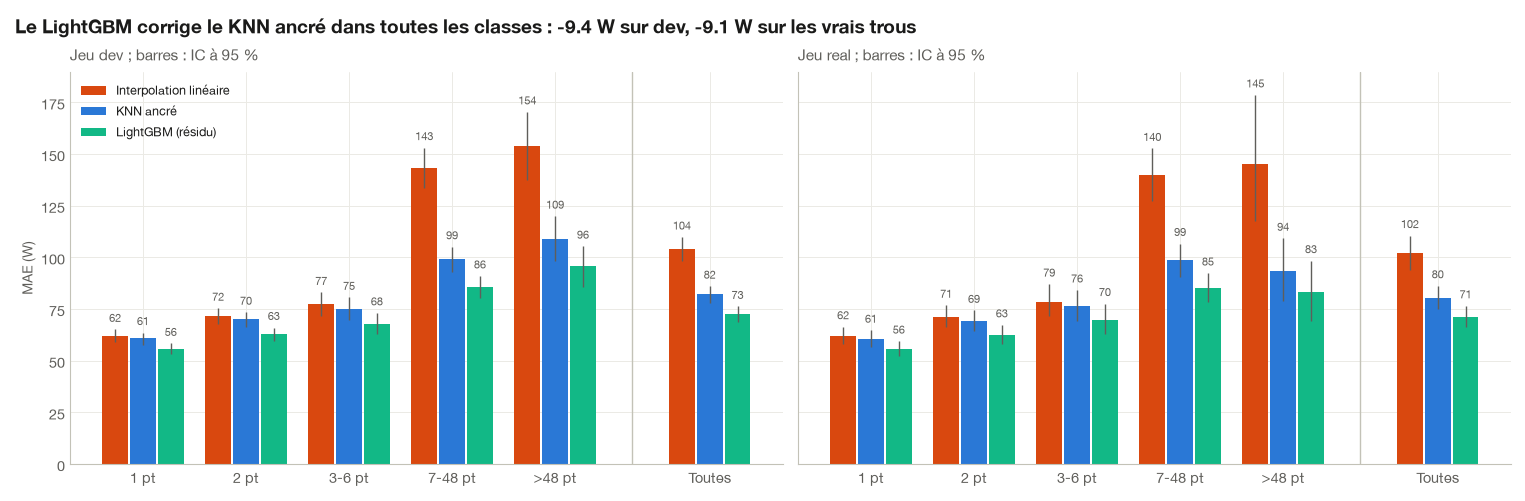

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
groups = [*LENGTH_LABELS, "toutes"]
x = np.arange(len(groups)) + np.array([0, 0, 0, 0, 0, 0.5])
for ax, (split_name, res) in zip(axes, [("dev", on_dev), ("real", on_real)], strict=True):
    for i, (name, r) in enumerate(res.items()):
        t = pd.concat(
            [
                r.by_class,
                pd.DataFrame(
                    {"mae": [r.mae], "low": [r.ci[0]], "high": [r.ci[1]]}, index=["toutes"]
                ),
            ]
        ).loc[groups]
        xs = x + (i - 1) * 0.27
        label = (
            name
            if name != "LightGBM"
            else f"LightGBM ({best_cfg.label.split(', ')[0].split()[-1]})"
        )
        ax.bar(xs, t["mae"], width=0.25, color=method_color(name), label=label)
        ax.errorbar(
            xs,
            t["mae"],
            yerr=[t["mae"] - t["low"], t["high"] - t["mae"]],
            fmt="none",
            ecolor=P["ink_secondary"],
            elinewidth=1,
        )
        for xi, v, hi in zip(xs, t["mae"], t["high"], strict=True):
            ax.text(
                xi,
                hi + 2.5,
                f"{v:.0f}",
                ha="center",
                va="bottom",
                fontsize=8,
                color=P["ink_secondary"],
            )
    ax.axvline(x[-1] - 0.75, color=P["axis"], lw=1)
    ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS] + ["Toutes"])
    ax.set_title(f"Jeu {split_name} ; barres : IC à 95 %")
    ax.set_ylim(0, 190)
axes[0].set_ylabel("MAE (W)")
axes[0].legend(loc="upper left", fontsize=9)
g_dev = gains.loc[("dev", "toutes"), "différence"]
g_real = gains.loc[("real", "toutes"), "différence"]
set_conclusion(
    fig,
    f"Le LightGBM corrige le KNN ancré dans toutes les classes : {g_dev:+.1f} W sur dev, "
    f"{g_real:+.1f} W sur les vrais trous",
)
save_fig(fig, "g1_mae_par_classe");

**Constat → conséquence (real)**

- **71,3 W sur les vrais trous**, avec un gain apparié sur le KNN ancré de **−9,1 W [−10,0 ; −8,3]**, quasi identique à dev. Ni le choix de la configuration ni l'entraînement sur des faux trous greffés ne sur-ajustent.
- Sur les trous de plus de 48 points de real, l'IC reste large (~±15 W) : il n'y a qu'environ 190 trous de ce type.
- **Depuis le benchmark (102,0 W sur real), l'erreur a baissé de 30 %.**

## e. Ce que le modèle a appris

,nb_dist,curve_mean,curve_std,knn_anchored,curve_zero_share,nb_std,lag_m48,lag_p48,knn_scaled,left_val
part du gain,0.70,0.17,0.03,0.02,0.02,0.01,0.01,0.01,0.00,0.00


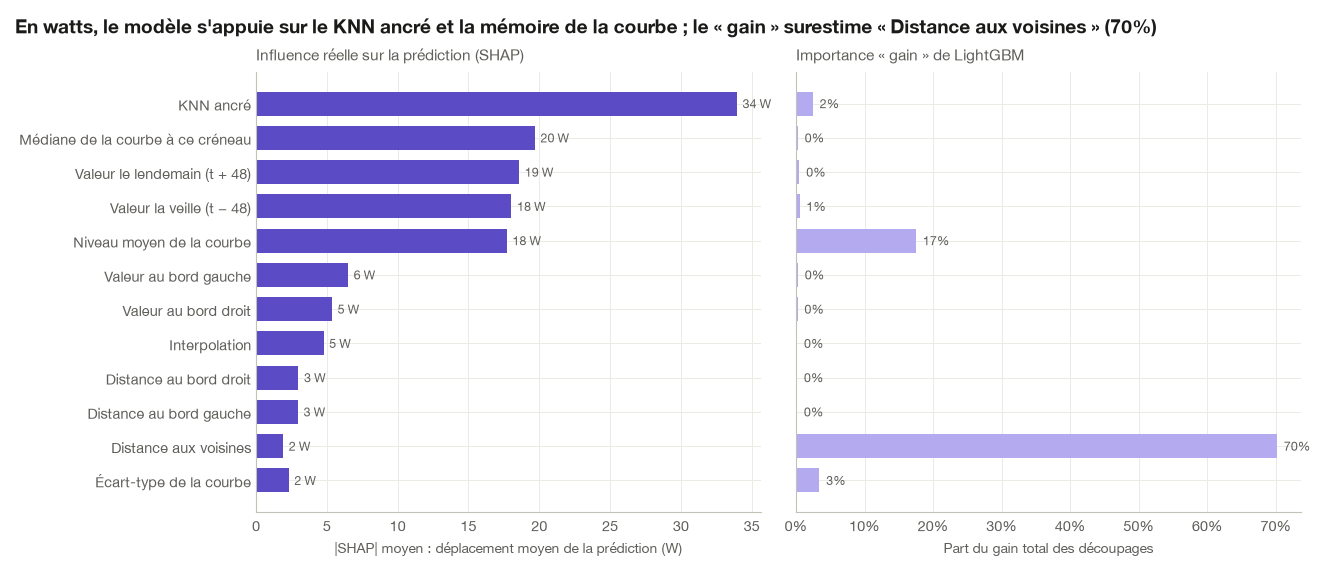

In [8]:
gain = pd.Series(trained[best_cfg].feature_importance("gain"), index=FEATURES)
gain = (gain / gain.sum()).sort_values(ascending=False)
display(gain.head(10).rename("part du gain").to_frame().T.round(3))

labels_fr = {
    "knn_anchored": "KNN ancré",
    "knn_scaled": "KNN non ancré",
    "interp": "Interpolation",
    "nb_std": "Écart-type des voisines",
    "nb_iqr": "Écart interquartile des voisines",
    "nb_dist": "Distance aux voisines",
    "hole_len": "Longueur du trou",
    "dist_left": "Distance au bord gauche",
    "dist_right": "Distance au bord droit",
    "rel_pos": "Position relative dans le trou",
    "hour_sin": "Heure (sinus)",
    "hour_cos": "Heure (cosinus)",
    "dow": "Jour de semaine",
    "weekend": "Week-end",
    "lag_m48": "Valeur la veille (t − 48)",
    "lag_p48": "Valeur le lendemain (t + 48)",
    "lag_m336": "Valeur 7 jours avant",
    "lag_p336": "Valeur 7 jours après",
    "slot_median": "Médiane de la courbe à ce créneau",
    "left_val": "Valeur au bord gauche",
    "right_val": "Valeur au bord droit",
    "curve_mean": "Niveau moyen de la courbe",
    "curve_std": "Écart-type de la courbe",
    "curve_zero_share": "Part de zéros de la courbe",
}
# Valeurs SHAP (TreeSHAP calculé par LightGBM, pred_contrib=True) sur 4 000 points de dev :
# contribution de chaque variable à la prédiction, en watts.
sample = rng.choice(len(feats_dev), 4000, replace=False)
Xs = feats_dev.iloc[sample]
contrib = trained[best_cfg].predict(Xs, pred_contrib=True)[:, :-1]  # dernière colonne : biais
mean_abs = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES).sort_values(ascending=False)

# Les 10 variables les plus influentes en watts, plus celles qui dominent le « gain » sans
# peser en watts (pour montrer l'écart entre les deux mesures)
shown = list(mean_abs.index[:10]) + [f for f in gain.index[:3] if f not in mean_abs.index[:10]]
order = pd.Index(shown[::-1])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
ax1.barh([labels_fr[f] for f in order], mean_abs[order].to_numpy(), color=P["data"], height=0.7)
for yi, v in enumerate(mean_abs[order].to_numpy()):
    ax1.text(v + 0.4, yi, f"{v:.0f} W", va="center", color=P["ink_secondary"], fontsize=9)
ax1.set_xlabel("|SHAP| moyen : déplacement moyen de la prédiction (W)")
ax1.set_title("Influence réelle sur la prédiction (SHAP)")
ax2.barh([labels_fr[f] for f in order], gain[order].to_numpy(), color=P["data_light"], height=0.7)
for yi, v in enumerate(gain[order].to_numpy()):
    ax2.text(v + 0.01, yi, f"{v:.0%}", va="center", color=P["ink_secondary"], fontsize=9)
ax2.xaxis.set_major_formatter(PercentFormatter(1))
ax2.set_xlabel("Part du gain total des découpages")
ax2.set_title("Importance « gain » de LightGBM")
top_gain = gain.index[0]
set_conclusion(
    fig,
    f"En watts, le modèle s'appuie sur le KNN ancré et la mémoire de la courbe ; le « gain » "
    f"surestime « {labels_fr[top_gain]} » ({gain.iloc[0]:.0%})",
)
save_fig(fig, "g2_importance_variables");

,knn_anchored,slot_median,lag_p48,lag_m48,curve_mean,left_val,right_val,interp,dist_right,dist_left
|SHAP| moyen (W),33.96,19.69,18.58,18.03,17.71,6.49,5.36,4.77,2.99,2.96


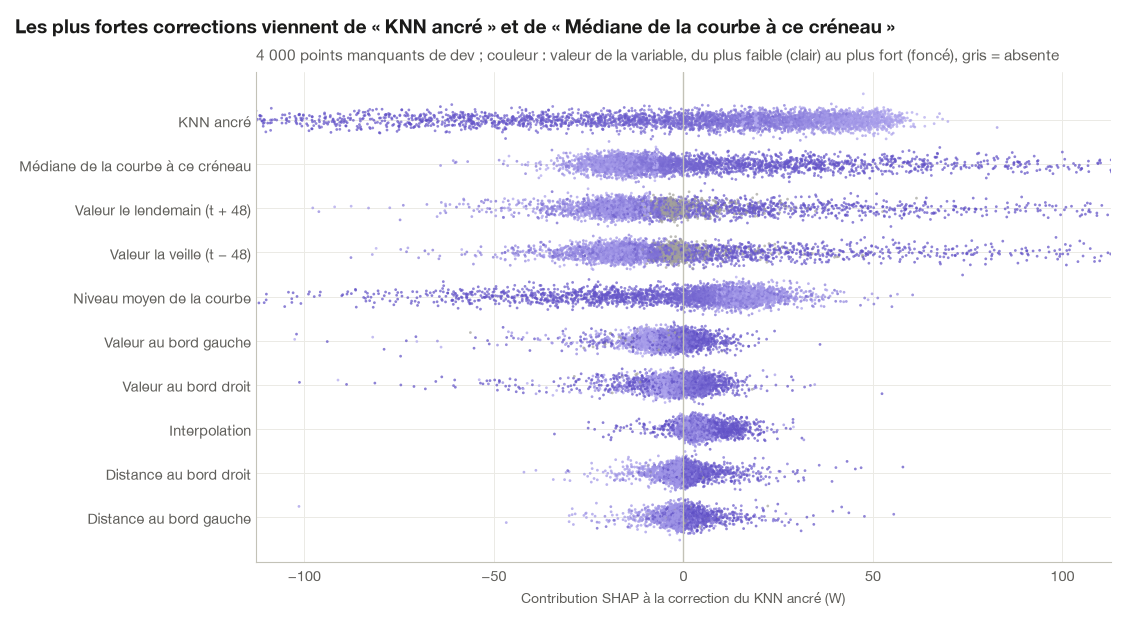

In [9]:
# Résumé SHAP (mêmes 4 000 points) : chaque point est un point manquant ; sa position dit de
# combien la variable a déplacé la prédiction, sa couleur la valeur de la variable.
top10 = mean_abs.index[:10]

fig, ax = plt.subplots(figsize=(11, 6))
cmap = LinearSegmentedColormap.from_list("violet", [P["data_light"], P["data"]])
for row_i, f in enumerate(top10[::-1]):
    j = FEATURES.index(f)
    vals = Xs[f].to_numpy()
    rank = pd.Series(vals).rank(pct=True).to_numpy()  # couleur : rang de la valeur (NaN : gris)
    jitter = rng.normal(0, 0.12, len(vals))
    colors = np.where(
        np.isnan(vals)[:, None], np.array(to_rgba(P["neutral"])), cmap(np.nan_to_num(rank))
    )
    ax.scatter(contrib[:, j], row_i + jitter, s=4, c=colors, lw=0, alpha=0.7)
ax.axvline(0, color=P["axis"], lw=1)
ax.set_yticks(range(10), [labels_fr[f] for f in top10[::-1]])
lim = np.percentile(np.abs(contrib[:, [FEATURES.index(f) for f in top10]]), 99.5)
ax.set_xlim(-lim, lim)
target_word = (
    "la correction du KNN ancré" if best_cfg.formulation == "residual" else "la prédiction"
)
ax.set_xlabel(f"Contribution SHAP à {target_word} (W)")
ax.set_title(
    "4 000 points manquants de dev ; couleur : valeur de la variable, du plus faible "
    "(clair) au plus fort (foncé), gris = absente"
)
set_conclusion(
    fig,
    f"Les plus fortes corrections viennent de « {labels_fr[top10[0]]} » "
    f"et de « {labels_fr[top10[1]]} »",
)
save_fig(fig, "g3_shap_resume")
display(mean_abs.head(10).rename("|SHAP| moyen (W)").to_frame().T.round(2))

**Constat → conséquence (interprétation)**

- **L'importance « gain » est trompeuse ici.** Elle attribue 70 % à « distance aux voisines », qui n'est même pas dans le top 10 SHAP. Avec l'objectif L1, LightGBM choisit ses découpages sur le signe des erreurs, puis recalcule chaque feuille comme une médiane : le gain mesure la qualité des découpages, pas leur effet en watts. Une variable comme la distance aux voisines sépare bien les courbes « faciles » des « difficiles » sans beaucoup déplacer la prédiction. **On lit donc l'influence avec SHAP.**
- **En watts, le modèle s'appuie sur** :
  - le KNN ancré (34 W en moyenne) ;
  - la **mémoire de la courbe** : sa médiane à ce créneau (20 W), sa valeur le lendemain (19 W) et la veille (18 W), au même créneau ;
  - son niveau moyen (18 W) ;
  - les valeurs aux bords du trou.
  
  C'est exactement l'information « même heure » que l'EDA désignait (autocorrélation de 0,46 à 24 h) et que le KNN ignorait.
- **La correction est un rappel vers la courbe elle-même.** Quand le KNN ancré prédit haut, la correction est négative ; quand la médiane de la courbe à ce créneau ou sa valeur de la veille sont hautes, elle est positive.

## f. Un exemple : un long trou rempli par les trois méthodes

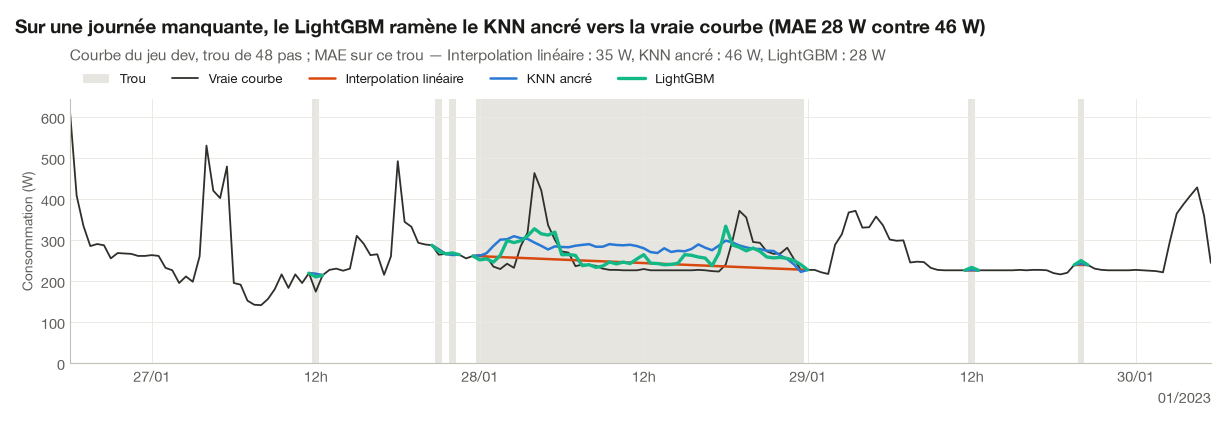

In [10]:
preds = {
    "Interpolation linéaire": linear_interpolation(dev.X_holed, dev.reservoir),
    "KNN ancré": anchored_knn(dev.X_holed, dev.reservoir),
    "LightGBM": make_method(trained[best_cfg], best_cfg)(dev.X_holed, dev.reservoir),
}
runs = hole_runs(dev.mask)
long = runs[runs["length"] == 48].copy()
y_arr = dev.y.to_numpy()
for name, pr in preds.items():
    arr = pr.to_numpy()
    long[name] = [
        np.abs(arr[s : s + n, c] - y_arr[s : s + n, c]).mean()
        for c, s, n in zip(long["curve"], long["start"], long["length"], strict=True)
    ]
# Exemple représentatif : trou entièrement intérieur (un jour de contexte de chaque côté),
# courbe de niveau entre la médiane et le 90e centile, gain du LightGBM sur le KNN ancré
# proche du gain médian positif
long["gain"] = long["KNN ancré"] - long["LightGBM"]
level = dev.y.mean().to_numpy()[long["curve"]]
inside = (long["start"] >= 48) & (long["start"] + long["length"] <= len(dev.y) - 48)
lo_lvl, hi_lvl = np.percentile(level, [50, 90])
pool = long[inside & (level > lo_lvl) & (level < hi_lvl) & (long["gain"] > 0)]
ex = pool.loc[(pool["gain"] - pool["gain"].median()).abs().idxmin()]
c, s, n = int(ex["curve"]), int(ex["start"]), int(ex["length"])
col = dev.X_holed.columns[c]
fig = plot_imputation(
    dev.y[col],
    {k: v[col] for k, v in preds.items()},
    dev.mask[:, c],
    f"Sur une journée manquante, le LightGBM ramène le KNN ancré vers la vraie courbe "
    f"(MAE {ex['LightGBM']:.0f} W contre {ex['KNN ancré']:.0f} W)",
    window=slice(max(0, s - 60), min(len(dev.y), s + n + 60)),
)
fig.axes[0].set_title(
    "Courbe du jeu dev, trou de 48 pas ; MAE sur ce trou — "
    + ", ".join(f"{k} : {ex[k]:.0f} W" for k in preds),
    pad=28,
)
save_fig(fig, "g4_exemple_long_trou");

## Suivre les runs dans MLflow

Chaque configuration de la grille est un run de l'expérience `04_lightgbm` : paramètres, MAE de validation croisée, nombre d'arbres, temps, importance des variables (`importance_gain.csv`), et — pour les modèles évalués — la MAE sur dev et real, globale et par classe. Tout est stocké localement dans `mlruns/` (ignoré par git).

Pour ouvrir l'interface, depuis la racine du projet :

```bash
uv run mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db
```

puis ouvrir http://127.0.0.1:5000 : choisir l'expérience `04_lightgbm`, cocher plusieurs runs et cliquer sur **Compare** pour les mettre côte à côte. `Ctrl+C` dans le terminal arrête l'interface.

## Constat → conséquence pour la modélisation

**Constat**
- **LightGBM résidu (63 feuilles, objectif L1, 1 480 arbres)** :
  - 72,7 W sur dev et 71,3 W sur real ;
  - par rapport au KNN ancré, −9,5 W sur dev et −9,1 W sur real (comparaisons appariées) ;
  - par rapport au benchmark, −30 %.
- Il est appris **sans jamais voir dev, holdout ni real** : 2,06 millions de points manquants greffés sur 8 000 courbes du réservoir, avec des prédictions KNN hors pli. Sa configuration est choisie par validation croisée groupée sur ces données ; dev n'a servi qu'à 3 évaluations.
- **Coût sur un MacBook Air M1** :
  - construction des données : 35 s ;
  - validation croisée en 3 plis : 9 min ;
  - entraînement final : 3 min ;
  - prédiction de 2 000 courbes : 13 s ;
  - grille complète (4 configurations) : 40 min.
  
  L'objectif L1, qui recalcule des médianes dans chaque feuille, est le poste le plus coûteux.
- Ce qui reste : 56 W sur les trous d'1 point, 86 à 96 W sur les trous longs.

**→ Conséquence**
- Le **LightGBM résidu devient la méthode de référence** (modèle en cache dans `data/processed/gbm_models/`).
- Prochaine étape : un **modèle deep learning à masquage**, qui voit toute la courbe et ses voisines d'un coup, au lieu de variables construites à la main. Il devra battre 72,7 W sur dev.
- Le désaccord des voisines et les valeurs SHAP donnent des pistes pour les **intervalles de confiance** (régression quantile LightGBM avec ces mêmes variables).
- Une version 255 feuilles, 2 fois plus rapide pour 0,02 W d'écart en CV, sera préférable si l'on doit réentraîner souvent (par exemple pour la démo Streamlit).